<a href="https://colab.research.google.com/github/EriTeo/Tarea-02---Introducci-n-a-visi-n-computacional/blob/main/Fashion_MNIST_Redes_Neuronales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica: Entrenamiento de una Red Neuronal con Fashion-MNIST
En este notebook se entrena una red neuronal utilizando el dataset **Fashion-MNIST**, empleando la capa `Flatten`, probando **3 configuraciones diferentes** y midiendo la métrica de **accuracy** (precisión).

In [4]:
!pip install -q importlib_resources

import tensorflow as tf
import tensorflow_datasets as tfds
import tensorflow.keras as keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# Cargar el dataset Fashion-MNIST
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

# Función de normalización para escalar los píxeles de [0, 255] a [0.0, 1.0]
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Aplicar normalización y optimización de rendimiento
train_ds = train_ds.map(normalize).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(normalize).prefetch(tf.data.AUTOTUNE)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.R63HWR_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.R63HWR_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.


## Definición y Entrenamiento de las 3 Configuraciones

In [6]:
# Función auxiliar para compilar, entrenar y retornar el historial de un modelo
def entrenar_modelo(modelo, nombre_config, epochs=5):
    print(f"\n--- Entrenando: {nombre_config} ---")
    modelo.compile(
        optimizer='adam',
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=['accuracy']
    )

    history = modelo.fit(
        train_ds,
        epochs=epochs,
        validation_data=test_ds
    )
    return history

# -------------------------------------------------------------------------
# Configuración 1: Red densa simple (1 capa oculta de 128 neuronas)
# -------------------------------------------------------------------------
modelo_1 = tf.keras.Sequential([
    layers.Flatten(input_shape=(28, 28, 1)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

historia_1 = entrenar_modelo(modelo_1, "Configuración 1 (1 capa de 128 neuronas)", epochs=5)

# -------------------------------------------------------------------------
# Configuración 2: Red más profunda (2 capas ocultas: 256 y 128 neuronas)
# -------------------------------------------------------------------------
modelo_2 = tf.keras.Sequential([
    layers.Flatten(input_shape=(28, 28, 1)),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

historia_2 = entrenar_modelo(modelo_2, "Configuración 2 (2 capas: 256 y 128 neuronas)", epochs=5)

# -------------------------------------------------------------------------
# Configuración 3: Red profunda con Dropout (256, 128 neuronas + Dropout 0.2)
# -------------------------------------------------------------------------
modelo_3 = tf.keras.Sequential([
    layers.Flatten(input_shape=(28, 28, 1)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

historia_3 = entrenar_modelo(modelo_3, "Configuración 3 (2 capas + Dropout 0.2)", epochs=5)


--- Entrenando: Configuración 1 (1 capa de 128 neuronas) ---
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.8226 - loss: 0.5006 - val_accuracy: 0.8377 - val_loss: 0.4537
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8632 - loss: 0.3790 - val_accuracy: 0.8504 - val_loss: 0.4115
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8770 - loss: 0.3394 - val_accuracy: 0.8634 - val_loss: 0.3775
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8850 - loss: 0.3136 - val_accuracy: 0.8686 - val_loss: 0.3620
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8923 - loss: 0.2940 - val_accuracy: 0.8720 - val_loss: 0.3578

--- Entrenando: Configuración 2 (2 capas: 256 y 128 neuronas) ---
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8275 - loss: 0.4741 - val_accuracy: 0.8437 - val_loss: 0.4271
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8682 - loss: 0.3569 - val_a

## Gráficas de Resultados en 2D (Accuracy y Loss)

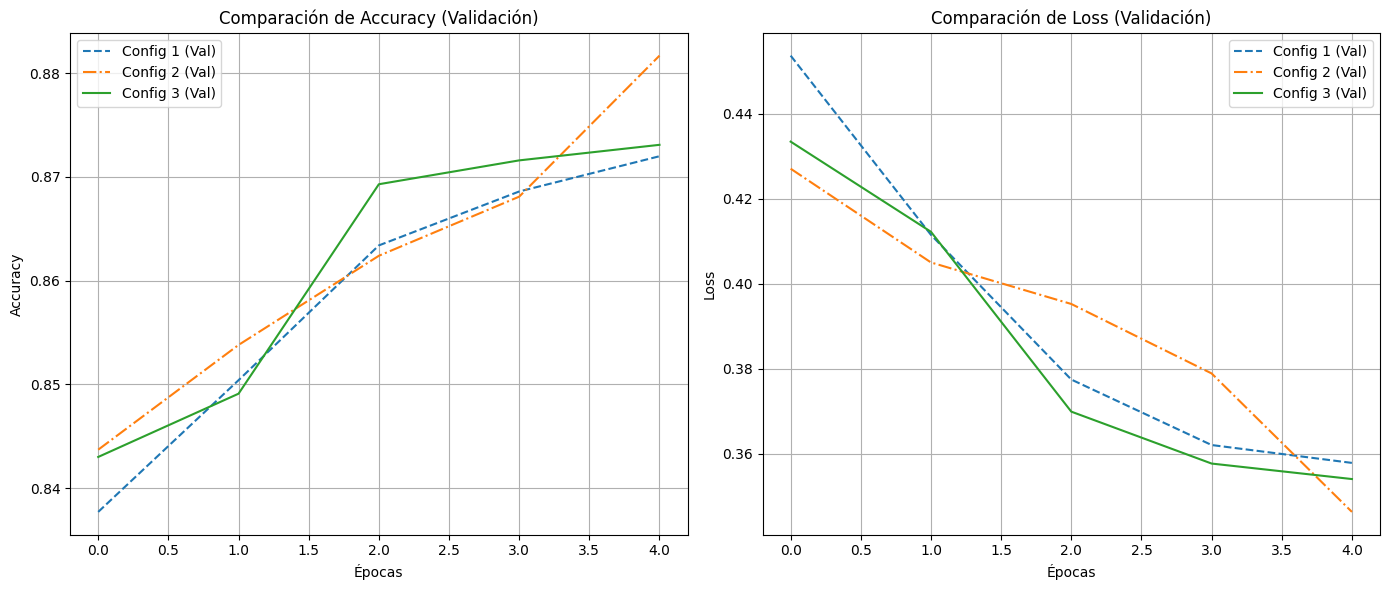

In [7]:
plt.figure(figsize=(14, 6))

# Gráfica de Accuracy (Precisión)
plt.subplot(1, 2, 1)
plt.plot(historia_1.history['val_accuracy'], label='Config 1 (Val)', linestyle='--')
plt.plot(historia_2.history['val_accuracy'], label='Config 2 (Val)', linestyle='-.')
plt.plot(historia_3.history['val_accuracy'], label='Config 3 (Val)', linestyle='-')
plt.title('Comparación de Accuracy (Validación)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfica de Loss (Pérdida)
plt.subplot(1, 2, 2)
plt.plot(historia_1.history['val_loss'], label='Config 1 (Val)', linestyle='--')
plt.plot(historia_2.history['val_loss'], label='Config 2 (Val)', linestyle='-.')
plt.plot(historia_3.history['val_loss'], label='Config 3 (Val)', linestyle='-')
plt.title('Comparación de Loss (Validación)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()